# E113: does patching the case readout flip the case-label fine-tune's answer?

*definition-lead, 2026-11-06. Report `reports/analyses/2026-11-06_analysis_e113-case-patch.md`; plan `reports/plans/2026-11-06_plan_e113-case-patch.md`. Follows E112, `reports/analyses/2026-11-06_analysis_e112-case-label.md`. Provisional: no independent check.*

## The answer

Patching the case readout reaches the model's own later reading of case, yet the fine-tuned label almost never follows. Setting block 1's case coordinate to the other case's value made block 2's case readout report the flipped case on seven windows in ten. Under the same patch the real fine-tune's label changed on about one window in a hundred, against a filed bar of one half. So the real task reads "not through C", and our filed "reuses C" missed a third time.


## What we were trying to test

E112 built a pair of fine-tunes of the 67M model to read the adopted reuse definition on, `decisions.md` rows 81 and 87 with nothing added. After a fixed marker token, the trigger, the **real task** says label A if the word before it is capitalised and B if not. The **twin** uses the same trigger and labels, but each word form gets its label from a seeded shuffle, so it can only memorise. Each has two seeds. E112's notebook, `notebooks/E112_case_label.ipynb`, describes the pair; we reuse its four saved fine-tuned states unchanged.

On the real task E112 passed every test but the causal one. A ridge readout trained on Pile text reads the previous word's case at block 1's output, the second of four blocks, with accuracy 0.994. The real fine-tune is right on held-out words and agrees with a cut on that readout. But removing the readout's direction took only a tenth to a fifth of the label gain, against a bar of one half. Row 81 words the causal check as "ablating **or patching** the readout direction breaks the fine-tuned behaviour". E113 runs the patching form, the user's choice after E112 closed.

**The patch.** At block 1's output we move one coordinate of the residual $h$ along a unit direction $u$ to the other case's typical value: $h \mapsto h + (\mu_{\text{opp}} - h^\top u)\,u$. Here $\mu_{\text{opp}}$ is the mean of $h^\top u$ over Pile windows whose word has the opposite case, computed once on the original model. We do this at two positions together:

- at the trigger, along E112's previous-word case readout;
- at the word itself, along a readout of the word's own case, refitted exactly as E112's first amendment fitted it.

Nothing else in the forward pass is touched. A capitalised word's window now carries a lower-case word's value on both coordinates, and the reverse.

**What is measured.**

- **Does the patch reach the next block?** This is the apparatus check, run first on the original model alone. E112's case readout at block 2, trained on Pile text, is read at the trigger on 1,600 held-out windows. We report the share it reads as the *flipped* case: 0.115 unpatched, since it reads the true case 0.885 of the time. A patch that works pushes it above 0.70; below that the run stops.
- **Does the label flip?** On each fine-tuned state, the share of the 1,024 training-word windows whose label changes sign under the patch. A label that is a function of the patched coordinate flips on most windows; one computed elsewhere flips on almost none.
- **Random-direction control.** The same step size per window, along seeded random directions at both positions, five draws per state. It shows how many labels any nudge of this size flips.
- **Damage.** The original model's next-token loss at the trigger on 9,600 Pile windows, patched minus unpatched.


In [1]:
from pathlib import Path

from IPython.display import Image, display

FIG = Path("../experiments/case_patch/figures")


## What we expected, and why

We expected the patch to reach block 2, because block 2's case readout already reads 0.885 and is built on block 1. We expected the real fine-tune's label to flip on at least half the training-word windows. The fine-tune carries to held-out words as a cut on the block-1 readout, so the simplest way for it to work is to read that coordinate. We expected the twin to flip on at most a fifth, since its labels do not depend on case. We expected random directions of the same size to flip almost nothing, and the patch to cost the original model under a tenth of a nat.


## Does the patch flip the case the model reads at the next block?


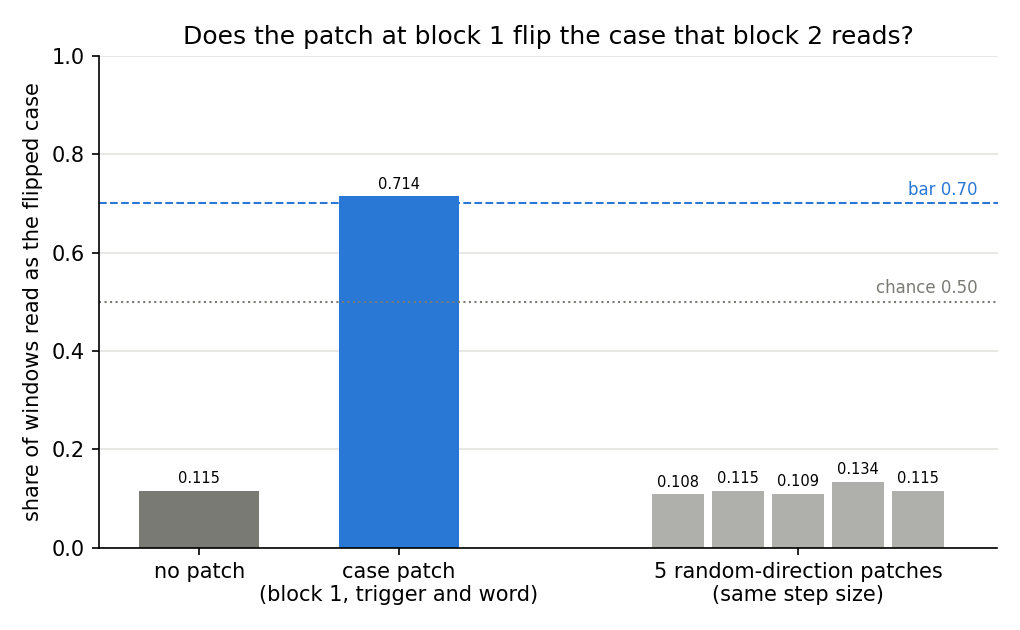

In [2]:
display(Image(FIG / "readout.png", width=750))


**Reading it.** Yes, on seven windows in ten. Unpatched, block 2's case readout reports the flipped case on 0.115 of held-out windows, its error rate. Under the case patch it reports the flipped case on 0.714, just over the filed bar of 0.70. Random patches of the same size leave it at 0.108 to 0.134, where it started. So the edit changes what the original model itself carries forward about case, and it does so through the case coordinate, not through the size of the nudge. The patch is cheap: the original model's next-token loss rose by 0.014 nats from 3.431, against 0.008 for a random patch. Three windows in ten still read the true case at block 2, so the flip downstream is partial.


## Does the fine-tuned label follow the patched case readout?


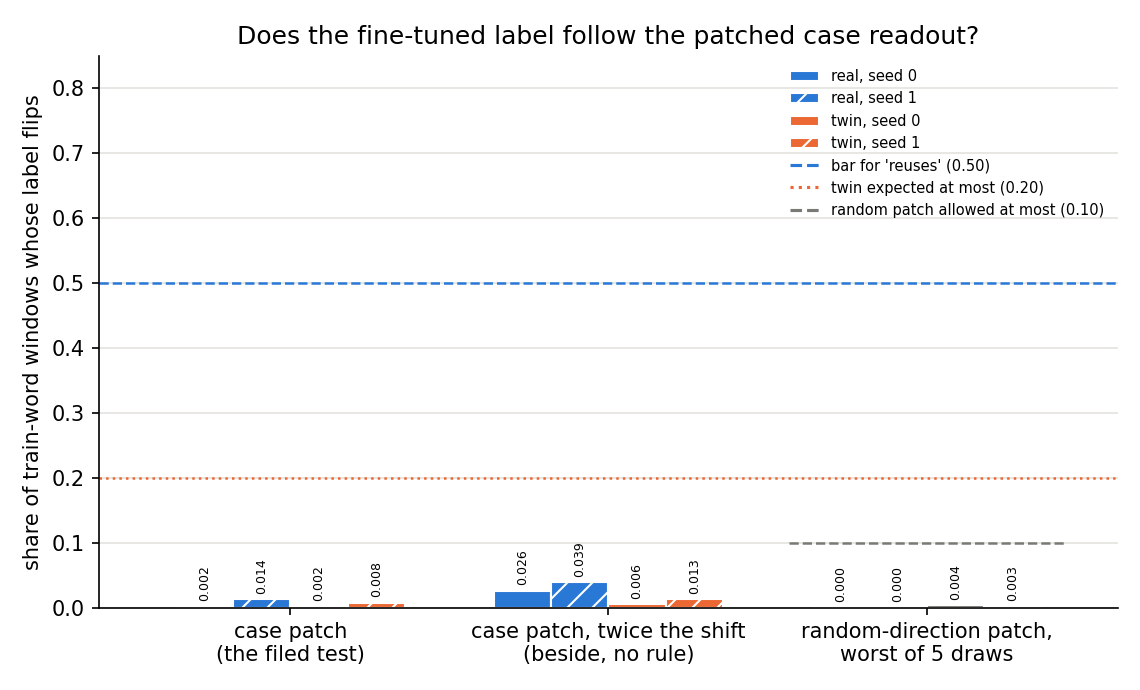

In [3]:
display(Image(FIG / "flips.png", width=850))


**Reading it.** No. The real fine-tune's label flipped on 0.002 and 0.014 of training-word windows, against the filed bar of 0.50. That is the size of the twin's 0.002 and 0.008, and barely above the random patches, which flipped at most 0.004 on any state. Doubling the shift past the other case's mean raised the real flips only to 0.026 and 0.039. Each edit alone, trigger or word, flipped under 0.006, and held-out words flipped under 0.004. So the readout the definition found carries case forward in the original model, but the fine-tuned label is computed from something the patch leaves in place.


## What we learned

Read under rows 81 and 87 with the causal check done by patching, the real case-label fine-tune reads "not through C" on both seeds. The twin reads "not through C", as filed. This is the pair's third causal reading, after E112's removal and its stronger removal. All three agree: taking the case readout away, or setting it to the other case, barely moves the label. The patch result is the sharper one, because the same patch does move the model's own case reading at block 2. For `GOALS.md`, the pair built to the definition's shape still gives no outside "reuse" label. A fine-tune that carries perfectly to unseen words as a cut on a pretrained feature need not run through that feature's linear readout.

## How compelling is the evidence

- Two seeds per arm, which agree to within 0.012 on the label flips.
- One block, two positions, one direction per position. The patch is blind to case carried in other directions, at other positions or blocks, or read nonlinearly.
- The patch reaches block 2 only partly, 0.714. Even if the label followed block 2's reading exactly, about seven flips in ten would be expected; one in a hundred was seen.
- Noise floor: random patches of the same step size flip at most 0.004 of labels and leave block 2's readout at its unpatched error rate.
- Label flips count sign changes only, not how far the label's margin moved.
- Training-word windows, where memorised word forms could also carry the label; held-out words flipped as rarely.

## Surprises

The filed prediction that the real fine-tune "reuses C" missed on both seeds, for the third time in this pair. We predicted at least half the labels would flip; about one in a hundred did, while the same patch flipped the model's block-2 case reading on seven windows in ten. We cannot explain it. Three candidates are open, all untested. The fine-tune may read the word's identity, or its case, through directions other than the readout's. The patch flips case downstream only partly. The label may be a nonlinear read of the word.

## What next

- The next step is the user's choice. E113 adds no rule; the definition is frozen at rows 81 and 87.
- A learned interchange subspace fitted on the original model would test whether case lives in a direction the ridge readout misses. If patching that subspace flipped the label, the readout, not the fine-tune, would be the gap.


## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| Q0 | the patch flips the original model's block-2 case reading | flipped share at least 0.70, else stop | 0.714; random 0.108-0.134 | pass |
| control | random patches flip almost no labels | at most 0.10, every draw, every state | at most 0.004 | pass |
| Q2 | the patch costs the original model little | printed, under 0.1 expected | +0.014 nats; random +0.008 | as expected |
| Q1 real | the real label follows the patch | flip share at least 0.50 | 0.002, 0.014 | **miss** |
| real verdict | "reuses C" on both seeds | E112's P1, P2 and Q1 | Q1 misses | **"not through C", filed outcome missed** |
| Q1 twin | the twin's label ignores the patch | at most 0.20 | 0.002, 0.008 | as filed |
| twin verdict | "not through C" on both seeds | any miss | P1, P2, Q1 miss | **"not through C", as filed** |

## Departures from the literature

- The causal check is our addition from row 81; Jain et al. 2024 use pruning and reverse fine-tuning.
- Standard activation patching copies a whole activation from a counterfactual input. We set one coordinate, along a ridge readout fitted on Pile text, to the other class's Pile mean on the original model. This is a one-direction interchange along a probe, not a subspace learned to make interchanges work, as in Geiger and colleagues' distributed alignment search.
- The class means are taken on the original model and used unchanged on every fine-tuned state, since the readout is defined on the original model.
- The block-2 readout check is our own positive control, with a bar set from E112's measured 0.885.

## Not run

- Subject number, the second pair.
- A learned interchange subspace fitted on the original model.
- The route-split readings, which subcomponents Γ switches on, at this trigger.
- Patching at blocks 2 or 3, or at other positions.
- Label margin under the patch; only sign flips are scored.
- An independent check. The next step is the user's decision, ask 6.

Provenance: `experiments/case_patch/results/run.json`, log `run.out`; job 54194, MATS cluster debug QoS, one L40, about a minute, $0, exit 0.
